### Desafío 5 - Predicción de cancelación de reserva

- Nombre: Jose Ignacio Kuoman Jimenez
- Generacion: G76

### Desafío de Validación: Redes Neuronales Multicapa

En este desafío validaremos nuestros conocimientos de la sesión. Para lograrlo, necesitarás desarrollar un modelo de red neuronal multicapa, al que deberás ajustar:

- Cantidad de neuronas.
- Cantidad de capas ocultas.
- Funciones de activación.
- Técnicas de regularización.

Este modelo será aplicado a un conjunto de datos de clientes que han realizado reservas en un hotel urbano y en un hotel turístico. El objetivo es **predecir si un cliente cancelará o no la reserva realizada.**

### Descripción de las Variables del Conjunto de Datos

- **hotel**: Hotel (H1 = Resort Hotel o H2 = City Hotel).
- **is_canceled**: Valor que indica si la reserva se canceló (1) o no (0).
- **lead_time**: Número de días transcurridos entre la fecha de entrada de la reserva en el PMS y la fecha de llegada.
- **arrival_date_year**: Año de la fecha de llegada.
- **arrival_date_month**: Mes de la fecha de llegada.
- **arrival_date_week_number**: Número de semana del año de la fecha de llegada.
- **arrival_date_day_of_month**: Día de la fecha de llegada.
- **stays_in_weekend_nights**: Número de noches de fin de semana (sábado o domingo) que el huésped se alojó o reservó para alojarse en el hotel.
- **stays_in_week_nights**: Número de noches entre semana (de lunes a viernes) que el cliente se alojó o reservó en el hotel.
- **adults**: Número de adultos.
- **children**: Número de niños.
- **babies**: Número de bebés.
- **meal**: Tipo de comida reservada. Las categorías se presentan en paquetes de comidas de hospitalidad estándar:
  - Undefined/SC: Sin paquete de comidas.
  - BB: Alojamiento y desayuno.
  - HB: Media pensión (desayuno y otra comida, normalmente cena).
  - FB: Pensión completa (desayuno, almuerzo y cena).
- **country**: País de origen. Las categorías se representan en el formato ISO 3166-3:2013.
- **market_segment**: Designación del segmento de mercado. En las categorías, el término TA significa agencias de viaje y TO operadores turísticos.
- **distribution_channel**: Canal de distribución de reservas. En las categorías, el término TA significa agencias de viaje y TO operadores turísticos.
- **is_repeated_guest**: Valor que indica si el nombre de la reserva era de un huésped repetido (1) o no (0).
- **previous_cancellations**: Número de reservas anteriores canceladas por el cliente antes de la reserva actual.
- **previous_bookings_not_canceled**: Número de reservas anteriores no canceladas por el cliente antes de la reserva actual.
- **reserved_room_type**: Código del tipo de habitación reservada. El código se presenta en lugar de la designación por razones de anonimato.
- **assigned_room_type**: Código del tipo de habitación asignado a la reserva.
- **booking_changes**: Número de cambios/enmiendas realizados en la reserva desde el momento en que se introdujo en el PMS.
- **deposit_type**: Indicación de si el cliente hizo un depósito para garantizar la reserva. Esta variable puede asumir tres categorías:
  - No Deposit: No se realizó ningún depósito.
  - Non Refund: Se realizó un depósito por valor del coste total de la estancia.
  - Refundable: Se realizó un depósito por valor inferior al coste total de la estancia.
- **agent**: ID de la agencia de viajes que realizó la reserva.
- **company**: ID de la empresa/entidad que realizó la reserva o responsable del pago de la reserva. La identificación se presenta en lugar de la designación por razones de anonimato.
- **days_in_waiting_list**: Número de días que la reserva estuvo en lista de espera antes de ser confirmada al cliente.
- **customer_type**: Tipo de reserva, asumiendo una de las cuatro categorías:
  - Contract: Cuando la reserva tiene asociada una adjudicación u otro tipo de contrato.
  - Group: Cuando la reserva está asociada a un grupo.
  - Transient: Cuando la reserva no forma parte de un grupo o contrato, y no está asociada a otra reserva transitoria.
  - Transient-party: Cuando la reserva es transitoria, pero está asociada al menos a otra reserva transitoria.
- **adr**: Tarifa media diaria, definida dividiendo la suma de todas las transacciones de alojamiento por el número total de noches de estancia.
- **required_car_parking_spaces**: Número de plazas de aparcamiento que necesita el cliente.
- **total_of_special_requests**: Número de peticiones especiales realizadas por el cliente (por ejemplo, cama doble o piso alto).
- **reservation_status**: Último estado de la reserva, asumiendo una de las tres categorías:
  - Canceled: El cliente ha cancelado la reserva.
  - Check-Out: El cliente se ha registrado pero ya se ha marchado.
  - No-Show: El cliente no se ha registrado y ha informado al hotel del motivo.
- **reservation_status_date**: Fecha en la que se estableció el último estado. Esta variable se puede utilizar junto con `reservation_status` para saber cuándo se cancela la reserva o cuándo abandona el cliente el hotel.

#### Descripción

#### Pregunta 1

1. Importa las librerías necesarias para aplicar preprocesamiento de datos, visualización y creación de un modelo de red neuronal feedforward con Keras y Tensorflow, además de las librerías para realizar regularización y búsqueda de grilla.

   Luego, debes descartar las columnas **index**, **arrival_date_year**, **agent**, **country**, **company**, **reservation_status** y **reservation_status_date**. Revisa después si la base de datos presenta valores ausentes; en el caso que existan deberás eliminar estos registros siempre y cuando la cantidad sea menor al 4% del total. En caso que sea superior, debes decidir si quitar la característica o imputar los datos faltantes aplicando alguna estrategia, que debes describir.

In [3]:
# Para el preprocesamiento de los datos y visualización de los datos
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [5]:
# Para realizar la estandarización de las variables regresoras
from sklearn.preprocessing import StandardScaler

In [9]:
# para la division del conjunto de datos de entrenamiento y de test
from sklearn.model_selection import train_test_split

In [11]:
from scipy.stats import chi2_contingency

In [7]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.layers import Dense
from sklearn.datasets import fetch_openml
from sklearn.metrics import classification_report
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, MinMaxScaler
from sklearn.model_selection import GridSearchCV
from scikeras.wrappers import KerasClassifier

# Las siguientes importaciones de optimizadores y funciones de inicialización de Keras estaban mal escritas
from keras.optimizers import SGD, Adagrad, Adadelta
from keras.models import Sequential
from keras.initializers import HeNormal, GlorotNormal
from keras.regularizers import l1, l2, l1_l2
from keras.constraints import MaxNorm

# Además, es recomendable actualizar la importación de Dropout, ya que puede generar un conflicto de nombres con scikit-learn
from keras.layers import Dropout

In [297]:
from keras.initializers import GlorotUniform

In [13]:
# para calcular las metricas del modelo
from sklearn.metrics import classification_report, accuracy_score, f1_score, roc_curve, roc_auc_score, confusion_matrix

In [15]:
df = pd.read_csv('hotel_bookings.csv', sep=',', encoding='utf-8')
df.head()

,index,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,0,Resort Hotel,0,342,2015,July,27,1,0,0,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,01-07-15
1,1,Resort Hotel,0,737,2015,July,27,1,0,0,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,01-07-15
2,2,Resort Hotel,0,7,2015,July,27,1,0,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,02-07-15
3,3,Resort Hotel,0,13,2015,July,27,1,0,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,02-07-15
4,4,Resort Hotel,0,14,2015,July,27,1,0,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,03-07-15


##### pregunta 1

Luego, debes descartar las columnas **index**, **arrival_date_year**, **agent**, **country**, **company**, **reservation_status** y **reservation_status_date**. Revisa después si la base está correcta para proceder.

In [17]:
df = df.drop(columns=['index','arrival_date_year','agent','country','company','reservation_status' ,'reservation_status_date'])

In [19]:
df.head()

,hotel,is_canceled,lead_time,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,...,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests
0,Resort Hotel,0,342,July,27,1,0,0,2,0.0,...,0,C,C,3,No Deposit,0,Transient,0.0,0,0
1,Resort Hotel,0,737,July,27,1,0,0,2,0.0,...,0,C,C,4,No Deposit,0,Transient,0.0,0,0
2,Resort Hotel,0,7,July,27,1,0,1,1,0.0,...,0,A,C,0,No Deposit,0,Transient,75.0,0,0
3,Resort Hotel,0,13,July,27,1,0,1,1,0.0,...,0,A,A,0,No Deposit,0,Transient,75.0,0,0
4,Resort Hotel,0,14,July,27,1,0,2,2,0.0,...,0,A,A,0,No Deposit,0,Transient,98.0,0,1


In [21]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 26 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_month              119390 non-null  object 
 4   arrival_date_week_number        119390 non-null  int64  
 5   arrival_date_day_of_month       119390 non-null  int64  
 6   stays_in_weekend_nights         119390 non-null  int64  
 7   stays_in_week_nights            119390 non-null  int64  
 8   adults                          119390 non-null  int64  
 9   children                        119386 non-null  float64
 10  babies                          119390 non-null  int64  
 11  meal                            119390 non-null  object 
 12  market_segment  

In [23]:
np.sort(df.columns)

array(['adr', 'adults', 'arrival_date_day_of_month', 'arrival_date_month',
       'arrival_date_week_number', 'assigned_room_type', 'babies',
       'booking_changes', 'children', 'customer_type',
       'days_in_waiting_list', 'deposit_type', 'distribution_channel',
       'hotel', 'is_canceled', 'is_repeated_guest', 'lead_time',
       'market_segment', 'meal', 'previous_bookings_not_canceled',
       'previous_cancellations', 'required_car_parking_spaces',
       'reserved_room_type', 'stays_in_week_nights',
       'stays_in_weekend_nights', 'total_of_special_requests'],
      dtype=object)

Vemos que las columnas que hemos removido: 'index','arrival_date_year','agent','country','company','reservation_status' y 'reservation_status_date' no se encuentran en el dataframe.

##### pregunta 1

El conjunto de datos presenta valores ausentes; en el caso que existan deberás eliminar estos registros siempre y cuando la cantidad sea menor al 4% del total. En caso que sea superior, debes decidir si quitar la característica o imputar los datos faltantes aplicando alguna estrategia, que debes describir.

In [25]:
# revisamos el % de valores ausentes en cada una de las columnas

df.isnull().mean() * 100

hotel                             0.00000
is_canceled                       0.00000
lead_time                         0.00000
arrival_date_month                0.00000
arrival_date_week_number          0.00000
arrival_date_day_of_month         0.00000
stays_in_weekend_nights           0.00000
stays_in_week_nights              0.00000
adults                            0.00000
children                          0.00335
babies                            0.00000
meal                              0.00000
market_segment                    0.00000
distribution_channel              0.00000
is_repeated_guest                 0.00000
previous_cancellations            0.00000
previous_bookings_not_canceled    0.00000
reserved_room_type                0.00000
assigned_room_type                0.00000
booking_changes                   0.00000
deposit_type                      0.00000
days_in_waiting_list              0.00000
customer_type                     0.00000
adr                               

##### Procedemos a ver la cantidad de valores nulos por columna

In [27]:
# Valores nulos en el DataFrame
missing_values = df.isnull().sum()

# Valores únicos en cada columna
unique_values = df.nunique()

# Procedemos a ver los valores nulos y la cantidad de valores únicos por columna
df_analysis = pd.DataFrame({'Missing Values': missing_values, 'Unique Values': unique_values})

In [29]:
df_analysis

,Missing Values,Unique Values
hotel,0,2
is_canceled,0,2
lead_time,0,479
arrival_date_month,0,12
arrival_date_week_number,0,53
arrival_date_day_of_month,0,31
stays_in_weekend_nights,0,17
stays_in_week_nights,0,35
adults,0,14
children,4,5


Vemos que solamente la columna 'children' tiene 4 valores nulos, representado solamente el 0.00335 de todos los datos.

Por lo cual, procedemos a eliminar solamente las 4 filas que tienen estos 4 valores nulos.

In [31]:
df = df.dropna()

Validamos que se haya dado correctamente

In [33]:
df.isnull().mean() * 100

hotel                             0.0
is_canceled                       0.0
lead_time                         0.0
arrival_date_month                0.0
arrival_date_week_number          0.0
arrival_date_day_of_month         0.0
stays_in_weekend_nights           0.0
stays_in_week_nights              0.0
adults                            0.0
children                          0.0
babies                            0.0
meal                              0.0
market_segment                    0.0
distribution_channel              0.0
is_repeated_guest                 0.0
previous_cancellations            0.0
previous_bookings_not_canceled    0.0
reserved_room_type                0.0
assigned_room_type                0.0
booking_changes                   0.0
deposit_type                      0.0
days_in_waiting_list              0.0
customer_type                     0.0
adr                               0.0
required_car_parking_spaces       0.0
total_of_special_requests         0.0
dtype: float

Vemos que se han eliminados todas las filas con valores nulos.

#### Pregunta 2

2. Realiza un análisis descriptivo y prepara los datos. Para esto:
   - a. Selecciona 5 variables que consideres relevantes (que no sean la variable **adr**) con respecto a cancelar una reserva.
   - b. Construye un histograma para la variable **adr** con reservas canceladas y no canceladas, y comenta el resultado.
   - c. Revisa la presencia de *outliers* para la variable **adr**. En caso que presente valores extremos, indica la cantidad de *outliers* por arriba y por abajo. Elimina sólo los tres valores más extremos en ambos casos; para los demás, cambia sus valores por el valor promedio de la variable.
   - d. Transforma las variables categóricas en variables *dummies*, estandariza las variables independientes con media igual a cero y desviación estándar 1, y realiza una división de los datos para entrenamiento y prueba, siendo este último el 33% de los registros.

In [35]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 119386 entries, 0 to 119389
Data columns (total 26 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119386 non-null  object 
 1   is_canceled                     119386 non-null  int64  
 2   lead_time                       119386 non-null  int64  
 3   arrival_date_month              119386 non-null  object 
 4   arrival_date_week_number        119386 non-null  int64  
 5   arrival_date_day_of_month       119386 non-null  int64  
 6   stays_in_weekend_nights         119386 non-null  int64  
 7   stays_in_week_nights            119386 non-null  int64  
 8   adults                          119386 non-null  int64  
 9   children                        119386 non-null  float64
 10  babies                          119386 non-null  int64  
 11  meal                            119386 non-null  object 
 12  market_segment       

##### Para seleccionar las 5 variables que considero relevantes, realizaré 2 proyectos principalmente:
- Realizaré un heatmap para ver la asociación de las variables regresoras númericas con la variable objetivo 
- Utilizaré la medida de asociación de Cramer's V para medir la fuerza de asociación entre 2 variables categóricas. La variable regresora categórica con la variable objetivo.

##### Procedemos a realizar el heatmap

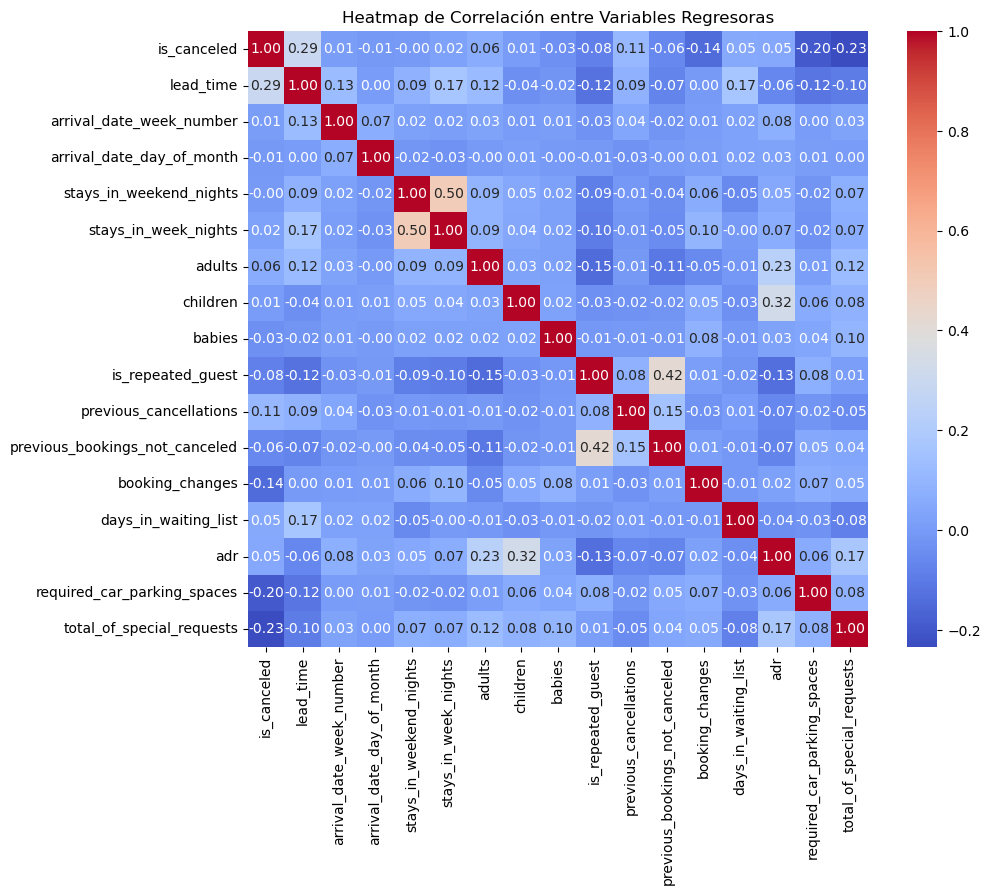

In [37]:
# Seleccionamos solamente las columnas númericas
# Por lo cual, seleccionamos solamente las columnas float e int.
numeric_df = df.select_dtypes(include=[float, int])

# Calculamos la matriz de correlación
correlation_matrix = numeric_df.corr()

# Creamos el heatmap de las correlaciones
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", cbar=True)
plt.title("Heatmap de Correlación entre Variables Regresoras")
plt.show()

Procedemos a utilizar **la medida de asociación de Cramer's V** para medir la fuerza de asociación entre 2 variables categóricas.

En este caso la vamos a utilizar para medir asociación de las variables regresoras categóricas con la variable objetivo, la cual es un variable categórica.

In [39]:
# procedemos a tener una lista solamente con las variables object de df
columnas_object = df.select_dtypes(include='object').columns.tolist()
columnas_object

['hotel',
 'arrival_date_month',
 'meal',
 'market_segment',
 'distribution_channel',
 'reserved_room_type',
 'assigned_room_type',
 'deposit_type',
 'customer_type']

In [41]:
# Esta funcion calcula la medida de asociacion Cramer's V
def medida_de_asociacion_cramer(var1, var2):
    table = pd.crosstab(var1, var2)
    # Se extrae solamente el valor estadístico chi-cuadrado
    chi2 = chi2_contingency(table)[0]
    n = table.sum().sum()
    r, c = table.shape
    return np.sqrt(chi2 / (n * (min(r, c) - 1)))

In [43]:
var_cats = ['hotel', 'meal', 'market_segment','distribution_channel','deposit_type','customer_type']

# Procedemos a medir la asociación de las variables regresoras categóricas con la variable objetivo.
corrs = {col: medida_de_asociacion_cramer(df[col], df['is_canceled']) for col in var_cats}

In [45]:
print(corrs)

{'hotel': 0.13648690375894748, 'meal': 0.05047555299018635, 'market_segment': 0.26675685927017484, 'distribution_channel': 0.17705368923999132, 'deposit_type': 0.4815109551543874, 'customer_type': 0.13652659622478963}


Viendo el heatmap, la cual tiene las variables regresoras númericas, y viendo el diccionario corrs, que contiene las variables regresoras categóricas, he seleccionado estas 5 variables que considero importante.

- 'lead_time'
- 'previous_cancellations'
- 'booking_changes'
- 'deposit_type'
- 'total_of_special_requests'

In [47]:
df_s = df[['is_canceled', 'lead_time', 'booking_changes', 'previous_cancellations', 'deposit_type' , 'total_of_special_requests','adr']]

##### De la pregunta 2
   
   - b. Construye un histograma para la variable **adr** con reservas canceladas y no canceladas, y comenta el resultado.

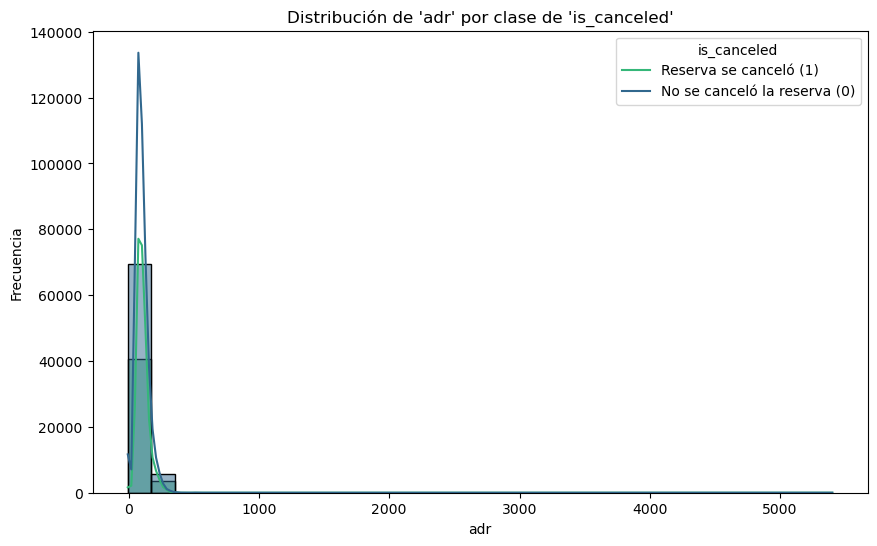

In [49]:
plt.figure(figsize=(10, 6))
sns.histplot(data=df, x='adr', hue='is_canceled', kde=True, bins=30, palette="viridis")
plt.title("Distribución de 'adr' por clase de 'is_canceled'")
plt.xlabel("adr")
plt.ylabel("Frecuencia")
plt.legend(title="is_canceled", labels=["Reserva se canceló (1)", "No se canceló la reserva (0)"])
plt.show()

Como no se puede observar bien, procedemos a graficar los histogramas individualmente.
- 1 histograma con la clase is_canceled = 0 - reserva no se cancelo
- 1 histograma con la clase is_canceled = 1 - reserva se cancelo

Recordar que adr viene a ser la tarifa media diaria, la cual está definida dividiendo la suma de todas las transacciones de alojamiento por el número total de noches de estancia.

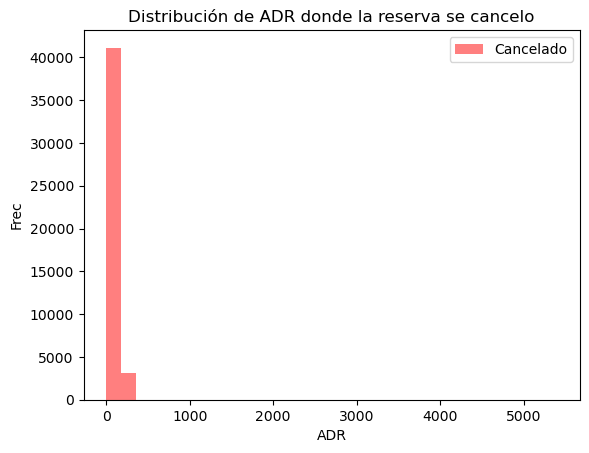

Procedemos a ver tambien como se encuentra distribuido ADR estadisticamente cuando la reserva se cancelo

count    44220.000000
mean       104.971148
std         52.568000
min          0.000000
25%         72.450000
50%         96.220000
75%        127.627500
max       5400.000000
Name: adr, dtype: float64


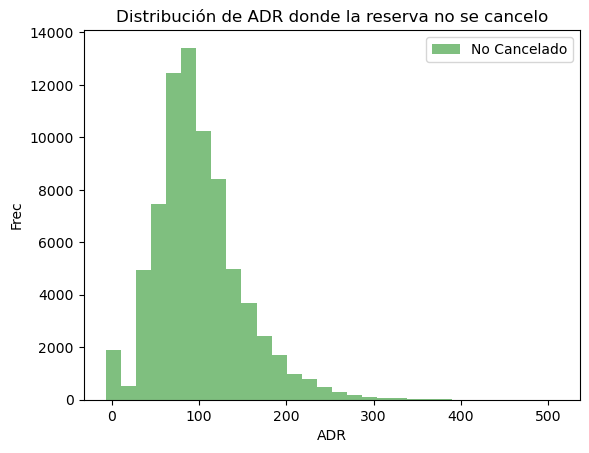

Procedemos a ver tambien como se encuentra distribuido ADR estadisticamente cuando la reserva no se cancelo

count    75166.000000
mean        99.987693
std         49.206263
min         -6.380000
25%         67.500000
50%         92.500000
75%        125.000000
max        510.000000
Name: adr, dtype: float64


In [51]:
adr_c = df[df['is_canceled'] == 1]['adr']
adr_no_c = df[df['is_canceled'] == 0]['adr']


plt.hist(adr_c, bins=30, alpha=0.5, label='Cancelado', color = 'red')
plt.xlabel("ADR")
plt.ylabel("Frec")
plt.title("Distribución de ADR donde la reserva se cancelo")
plt.legend()
plt.show()
print('Procedemos a ver tambien como se encuentra distribuido ADR estadisticamente cuando la reserva se cancelo\n')
print(adr_c.describe())

plt.hist(adr_no_c, bins=30, alpha=0.5, label='No Cancelado', color = 'green')
plt.xlabel("ADR")
plt.ylabel("Frec")
plt.title("Distribución de ADR donde la reserva no se cancelo")
plt.legend()
plt.show()
print('Procedemos a ver tambien como se encuentra distribuido ADR estadisticamente cuando la reserva no se cancelo\n')
print(adr_no_c.describe())
#adr: Tarifa media diaria definida dividiendo la suma de todas las transacciones de 
#alojamiento por el número total de noches de estancia.

##### Comentarios

- Podemos ver que los datos de la variable 'adr' se concentran en 100 en ambos gráficos, cancelados como no cancelados.
- Podemos ver que ambos gráficos existen valores atípicos de 'adr'. Por un lado, en el gráfico donde la reservas no se cancelaron existen valores negativos de 'adr' como también valores de 'adr' altos muy atípicos. Por otro lado, en el gráfico existen valores de 'adr' extremadamente altos por ejemplo su valor máximo es de 5400.


##### De la pregunta 2
   - c. Revisa la presencia de *outliers* para la variable **adr**. En caso que presente valores extremos, indica la cantidad de *outliers* por arriba y por abajo. Elimina sólo los tres valores más extremos en ambos casos; para los demás, cambia sus valores por el valor promedio de la variable.

In [53]:
df_s.head()

,is_canceled,lead_time,booking_changes,previous_cancellations,deposit_type,total_of_special_requests,adr
0,0,342,3,0,No Deposit,0,0.0
1,0,737,4,0,No Deposit,0,0.0
2,0,7,0,0,No Deposit,0,75.0
3,0,13,0,0,No Deposit,0,75.0
4,0,14,0,0,No Deposit,1,98.0


In [55]:
df_s.sort_values(by='adr')

,is_canceled,lead_time,booking_changes,previous_cancellations,deposit_type,total_of_special_requests,adr
14969,0,195,2,0,No Deposit,0,-6.38
0,0,342,3,0,No Deposit,0,0.00
2534,1,28,0,0,No Deposit,0,0.00
2536,1,28,0,0,No Deposit,0,0.00
33283,0,0,0,0,No Deposit,0,0.00
...,...,...,...,...,...,...,...
13142,1,378,0,0,No Deposit,0,450.00
103912,0,81,1,0,No Deposit,4,451.50
15083,0,1,0,0,No Deposit,0,508.00
111403,0,0,0,0,No Deposit,0,510.00


In [57]:
df_s.shape

(119386, 7)

##### Procedemos a eliminar los 3 primeros outliers que se encuentran arriba y los 3 últimos outliers que se encuentran debajo

In [59]:
#Primero saca los 3 extremos para tener un promedio mejor
df_s = df_s.sort_values(by='adr')

# Procedemos a crear un nuevo dataframe que contiene todas las filas de df_s a excepción de las 3 primeras filas y las últimas 3 filas.
# Para no modificar df_s, procedemos a realizar una copia de df_s con los cambios realizados.
df_f = df_s.iloc[3:-3].copy()

In [61]:
df_f.shape

(119380, 7)

##### Validamos de que se haya dado correctamente

In [63]:
df_f.head()

,is_canceled,lead_time,booking_changes,previous_cancellations,deposit_type,total_of_special_requests,adr
2536,1,28,0,0,No Deposit,0,0.0
33283,0,0,0,0,No Deposit,0,0.0
101624,0,32,0,0,No Deposit,1,0.0
2595,0,11,0,0,No Deposit,1,0.0
33205,0,94,0,0,No Deposit,0,0.0


In [65]:
df_f.tail()

,is_canceled,lead_time,booking_changes,previous_cancellations,deposit_type,total_of_special_requests,adr
39568,0,104,2,0,No Deposit,1,402.00
39155,0,31,0,0,No Deposit,2,426.25
13391,1,59,1,0,No Deposit,0,437.00
13142,1,378,0,0,No Deposit,0,450.00
103912,0,81,1,0,No Deposit,4,451.50


##### Para los demás outliers procedemos a cambiar sus valores por el valor promedio de la variable.

In [67]:
Q1 = df_f['adr'].quantile(0.25)
Q3 = df_f['adr'].quantile(0.75)
IQR = Q3 - Q1

# Calculo del imite inferior
li = Q1 - 1.5 * IQR

# Calculo del limite superior
ls = Q3 + 1.5 * IQR

outliers_abajo = (df_f['adr'] < li).sum()  # cuantos valores son menores que el limite inferior
outliers_arriba = (df_f['adr'] > ls).sum() # cuantos valores son mayores que el limite superior

prom_adr = df_f['adr'].mean()              # calculamos la media de 'adr' para reemplazarlo por los outliers

 # procedemos a reemplazar los outliers por la media (media de 'adr')

df_f['adr'] = np.where(
    (df_f['adr'] < li) | (df_f['adr'] > ls),  # si el valor se encuentra por debajo de li o arriba de ls se cambia por el promedio, caso contrario no hay ningun cambio
    prom_adr,  
    df_f['adr']  
)

print("Número de outliers por abajo :", outliers_abajo)
print("Número de outliers por arriba:", outliers_arriba)

Número de outliers por abajo : 0
Número de outliers por arriba: 3790


##### De la pregunta 2
   - d. Transforma las variables categóricas en variables *dummies*, estandariza las variables independientes con media igual a cero y desviación estándar 1, y realiza una división de los datos para entrenamiento y prueba, siendo este último el 33% de los registros.

In [69]:
df_f.head()

,is_canceled,lead_time,booking_changes,previous_cancellations,deposit_type,total_of_special_requests,adr
2536,1,28,0,0,No Deposit,0,0.0
33283,0,0,0,0,No Deposit,0,0.0
101624,0,32,0,0,No Deposit,1,0.0
2595,0,11,0,0,No Deposit,1,0.0
33205,0,94,0,0,No Deposit,0,0.0


In [71]:
df_f.info()

<class 'pandas.core.frame.DataFrame'>
Index: 119380 entries, 2536 to 103912
Data columns (total 7 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   is_canceled                119380 non-null  int64  
 1   lead_time                  119380 non-null  int64  
 2   booking_changes            119380 non-null  int64  
 3   previous_cancellations     119380 non-null  int64  
 4   deposit_type               119380 non-null  object 
 5   total_of_special_requests  119380 non-null  int64  
 6   adr                        119380 non-null  float64
dtypes: float64(1), int64(5), object(1)
memory usage: 7.3+ MB


In [73]:
df_f_dummy = pd.get_dummies(df_f.select_dtypes(['object']), dtype=int, drop_first=True)

Procedemos a estandarizar las variables independientes númericas con media igual a cero y desviación estándar 1

In [75]:
scaler = StandardScaler()
df_scaled = scaler.fit_transform(df_f[['lead_time','booking_changes','previous_cancellations','total_of_special_requests','adr']])

# Colocammos los datos en el DataFrame
df_scaled = pd.DataFrame(df_scaled, columns = ['lead_time','booking_changes','previous_cancellations','total_of_special_requests','adr'], index=df_f.index)

# Colocamos la variable objetivo en el DataFrame
df_scaled['is_canceled'] = df_f['is_canceled']

df_scaled

,lead_time,booking_changes,previous_cancellations,total_of_special_requests,adr,is_canceled
2536,-0.711340,-0.338966,-0.103184,-0.720693,-2.431686,1
33283,-0.973361,-0.338966,-0.103184,-0.720693,-2.431686,0
101624,-0.673908,-0.338966,-0.103184,0.540652,-2.431686,0
2595,-0.870424,-0.338966,-0.103184,0.540652,-2.431686,0
33205,-0.093719,-0.338966,-0.103184,-0.720693,-2.431686,0
...,...,...,...,...,...,...
39568,-0.000140,2.727323,-0.103184,0.540652,0.114909,0
39155,-0.683266,-0.338966,-0.103184,1.801997,0.114909,0
13391,-0.421245,1.194178,-0.103184,-0.720693,0.114909,1
13142,2.563921,-0.338966,-0.103184,-0.720693,0.114909,1


In [77]:
df_scaled.isnull().mean() * 100

lead_time                    0.0
booking_changes              0.0
previous_cancellations       0.0
total_of_special_requests    0.0
adr                          0.0
is_canceled                  0.0
dtype: float64

In [79]:
df_concat = pd.concat([df_scaled, df_f_dummy], axis = 1)
df_concat.head(5)

,lead_time,booking_changes,previous_cancellations,total_of_special_requests,adr,is_canceled,deposit_type_Non Refund,deposit_type_Refundable
2536,-0.711340,-0.338966,-0.103184,-0.720693,-2.431686,1,0,0
33283,-0.973361,-0.338966,-0.103184,-0.720693,-2.431686,0,0,0
101624,-0.673908,-0.338966,-0.103184,0.540652,-2.431686,0,0,0
2595,-0.870424,-0.338966,-0.103184,0.540652,-2.431686,0,0,0
33205,-0.093719,-0.338966,-0.103184,-0.720693,-2.431686,0,0,0


Procedemos a realizar una división de los datos para entrenamiento y prueba, siendo para prueba el 33% de los registros.

In [81]:
X = df_concat.loc[:, df_concat.columns != 'is_canceled']
y = df_concat['is_canceled']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.33, random_state=1234)

Validamos que la division se haya dado correctamente por medio de ver si hay valores nulos en y_train e y_test

In [83]:
print("Número de NaN en y_train:", np.isnan(y_train).sum())

Número de NaN en y_train: 0


In [85]:
print("Número de NaN en y_test:", np.isnan(y_test).sum())

Número de NaN en y_test: 0


#### Pregunta 3

3. Implementa dos modelos de red neuronal multicapa, considerando las siguientes características:
    - a. Cada modelo debe contar con tres capas ocultas.
    - b. El primer modelo debe tener funciones de activación **tanh**, **relu** y **tanh** en las capas ocultas, mientras que el segundo sólo funciones **tanh** en sus capas ocultas.
    - c. Cada modelo debe tener un mínimo de 20 neuronas para cada capa oculta. Usa un optimizador **SGD**, con 10 épocas de entrenamiento; cada capa deberá tener una neurona de sesgo. Debes decidir cómo se inicializan los pesos y el sesgo en cada capa oculta y de salida.

Muestra los resultados en un gráfico que tendrá una curva de *accuracy* para cada modelo en cada época de entrenamiento. Cada modelo debe lograr un *accuracy* superior al 75%. Concluye de acuerdo a los resultados.

#### Implementamos el primer modelo de red neuronal multicapa, considerando las siguiente características:

- Debe contar con 3 capas ocultas
- Debe de tener funciones de activación **tanh**, **relu** y **tanh** en sus capas ocultas
- Un mínimo de 20 neuronas para cada capa oculta.
- Usar un optimizador SGD, con 10 épocas de entrenamiento
- Cada capa deberá de tener una neurona de sesgo
- Debes decidir como se inicializan los pesos y el sesgo en cada capa oculta y de salida.

In [185]:
def create_model_1( n_neurons=80,  meta={}):
    n_features_in_ = meta["n_features_in_"]
    X_shape_ = meta["X_shape_"]
    
    ann_tmp = Sequential()

    ann_tmp.add(keras.Input(shape=(n_features_in_, )))
    
    n_hidden_layers = 3
    hl=3
    
    activation_fn = ['tanh','relu','tanh']
    
    for hl in range(n_hidden_layers):
    
        ann_tmp.add(
            Dense(
                units=n_neurons,
                use_bias=True,
                activation=activation_fn[hl],
                kernel_initializer=GlorotNormal(seed=2)
            )
        )
         
    ann_tmp.add(
        Dense(
            units=1,
            activation='sigmoid',
            kernel_initializer=GlorotNormal(seed=2),
            bias_initializer='zeros'
        )
    )
    return ann_tmp

In [187]:
clf = KerasClassifier(
    create_model_1,
    loss='binary_crossentropy',
    optimizer='SGD',
    verbose=1,
    metrics=['accuracy'],
    validation_split=.33
)

In [212]:
param_grid_1 = {
    'model__n_neurons': [20,30, 40,50,100],
    'batch_size': [300],
    'epochs': [10],
    'optimizer__learning_rate': [0.07,0.01,0.05,0.025,0.09,0.1]
}
grid = GridSearchCV(estimator=clf, param_grid=param_grid_1,
    scoring='accuracy', cv=3, verbose=0, n_jobs=-1)

grid_result = grid.fit(X_train, y_train)

Epoch 1/10
179/179 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - accuracy: 0.6807 - loss: 0.5773 - val_accuracy: 0.7413 - val_loss: 0.4406
Epoch 2/10
179/179 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7593 - loss: 0.4246 - val_accuracy: 0.8021 - val_loss: 0.3977
Epoch 3/10
179/179 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8111 - loss: 0.3858 - val_accuracy: 0.8139 - val_loss: 0.3594
Epoch 4/10
179/179 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8253 - loss: 0.3481 - val_accuracy: 0.8098 - val_loss: 0.3361
Epoch 5/10
179/179 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8290 - loss: 0.3245 - val_accuracy: 0.8367 - val_loss: 0.3150
Epoch 6/10
179/179 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8411 - loss: 0.3083 - val_accuracy: 0.8499 - val_loss: 0.2984
Epoch 7/10
179/179 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8452 - loss: 0.2943 - val_accuracy: 0.8429 - val_loss: 0.2911
Epoch 8/10
179/179 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8517 - loss: 0.2838 - val_accuracy: 0

In [215]:
print("\n\nBest: %f using %s" % (grid_result.best_score_, grid_result.best_params_))



Best: 0.872065 using {'batch_size': 300, 'epochs': 10, 'model__n_neurons': 50, 'optimizer__learning_rate': 0.07}


In [217]:
def viz_loss(history):
    epochs_ = len(history['accuracy'])
    fig, ax = plt.subplots(1, 2, figsize=(10, 4))
    ax[0].plot(history['accuracy'])
    ax[0].plot(history['val_accuracy'])
    ax[0].set_xticks(np.arange(epochs_), np.arange(1, epochs_+1))
    ax[0].set_title('model accuracy')
    ax[0].set_ylabel('accuracy')
    ax[0].set_xlabel('epoch')
    ax[0].legend(['train', 'test'], loc='lower right')


    ax[1].plot(history['loss'])
    ax[1].plot(history['val_loss'])
    ax[1].set_xticks(np.arange(epochs_), np.arange(1, epochs_+1))
    ax[1].set_title('model loss')
    ax[1].set_ylabel('loss')
    ax[1].set_xlabel('epoch')
    ax[1].legend(['train', 'test'], loc='upper center')

    plt.tight_layout()
    plt.show()

Mostramos los resultados en un gráfico de curva accuracy en cada época de entrenamiento

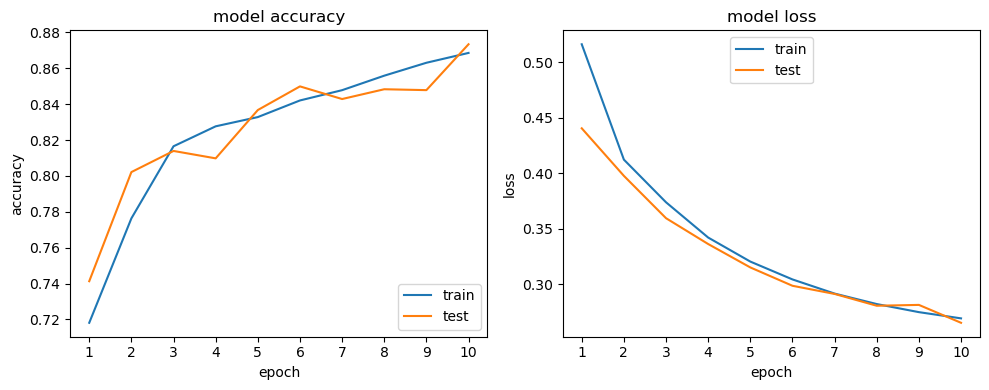

In [219]:
viz_loss(dict(grid_result.best_estimator_.history_))

In [221]:
predicciones = pd.DataFrame(data=grid_result.predict_proba(X_test), columns=['pred_0', 'pred_1'])

132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


##### Calculamos el AUC

In [223]:
auc = roc_auc_score(y_test, predicciones['pred_1'])
print(f"AUC: {auc:.3f}")

AUC: 0.947


##### Calculamos la Curva ROC

In [226]:
fpr, tpr, thresholds = roc_curve(y_test, predicciones['pred_1'])

##### Graficamos de la curva ROC

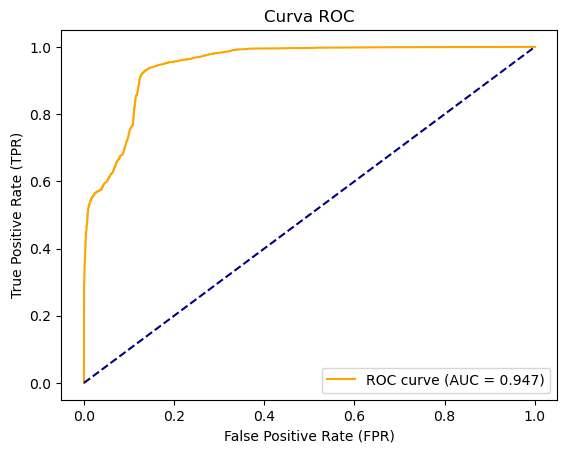

El área bajo la curva en TEST es:  0.9465235813803228


In [229]:
plt.figure()
plt.plot(fpr, tpr, color='orange', label=f'ROC curve (AUC = {auc:.3f})')
plt.plot([0, 1], [0, 1], color='navy', linestyle='--')  # Línea de referencia
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('Curva ROC')
plt.legend(loc="lower right")
plt.show()

print('El área bajo la curva en TEST es: ', auc)

##### Determinamos el umbral óptimo

- optimal_idx -> se busca el índice donde la diferencia (tpr-fpr) es máxima
- optimal_threshold -> Valor del umbral correspondiente a ese indice, y se va a usar para convertir las probabilidades en etiquetas binarias

In [235]:
optimal_idx = np.argmax(tpr - fpr)
optimal_threshold = thresholds[optimal_idx]

##### Convertimos las probabilidades en etiquetas usando el umbral óptimo

- Si la probabilidad de la clase 1 es mayor que optimal_threshold, se asigna la etiqueta 1.
- De no ser el caso, se asigna 0.

In [239]:
y_test_pred = np.where(predicciones['pred_1'] > optimal_threshold, 1, 0)

##### Evaluamos el desempeño del modelo

In [242]:
print('Los métricas usando el thereshold óptimo son: ')
print(classification_report(y_test, y_test_pred))    
print('La matriz de confusión: ')
print(confusion_matrix(y_test, y_test_pred))

Los métricas usando el thereshold óptimo son: 
              precision    recall  f1-score   support

         0.0       0.95      0.87      0.91     24742
         1.0       0.80      0.93      0.86     14650

    accuracy                           0.89     39392
   macro avg       0.88      0.90      0.88     39392
weighted avg       0.90      0.89      0.89     39392

La matriz de confusión: 
[[21440  3302]
 [ 1066 13584]]


Podemos ver que el primer modelo logró tener un accuracy de 0.89, lo cual indica que tiene un muy buena precisión.

Cade destacar que este modelo le implementamos la búsqueda de grilla para aumentar el accuracy de no haber sido así, la precisión del modelo hubiera sido más baja.

De igual manera, al segundo modelo también le vamos a implementar búsqueda de grilla para aumentar la precisión.

#### Implementamos el segundo modelo de red neuronal multicapa, considerando las siguiente características:

- Debe contar con 3 capas ocultas
- Solamente debe de tener funciones **tanh** en sus capas ocultas
- Un mínimo de 20 neuronas para cada capa oculta.
- Usar un optimizador SGD, con 10 épocas de entrenamiento
- Cada capa deberá de tener una neurona de sesgo
- Debes decidir como se inicializan los pesos y el sesgo en cada capa oculta y de salida.

In [245]:
def create_model_2( n_neurons=80,  meta={}):
    n_features_in_ = meta["n_features_in_"]
    X_shape_ = meta["X_shape_"]
    
    ann_tmp = Sequential()

    ann_tmp.add(keras.Input(shape=(n_features_in_, )))
    
    n_hidden_layers = 3
    hl=3
    
    activation_fn = ['tanh','tanh','tanh']
    
    for hl in range(n_hidden_layers):
    
        ann_tmp.add(
            Dense(
                units=n_neurons,
                use_bias=True,
                activation=activation_fn[hl],
                kernel_initializer=GlorotNormal(seed=2)
            )
        )
         
    ann_tmp.add(
        Dense(
            units=1,
            activation='sigmoid',
            kernel_initializer=GlorotNormal(seed=2),
            bias_initializer='zeros'
        )
    )
    return ann_tmp

In [247]:
clf2 = KerasClassifier(
    create_model_2,
    loss='binary_crossentropy',
    optimizer='SGD',
    verbose=1,
    metrics=['accuracy'],
    validation_split=.33
)

In [249]:
param_grid2 = {
    'model__n_neurons': [20,30, 40,50,100],
    'batch_size': [300],
    'epochs': [10],
    'optimizer__learning_rate': [0.07,0.01,0.05,0.025,0.09,0.1]
}
grid2 = GridSearchCV(estimator=clf2, param_grid=param_grid2,
    scoring='accuracy', cv=3, verbose=0, n_jobs=-1)

grid_result2 = grid2.fit(X_train, y_train)

Epoch 1/10
179/179 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7331 - loss: 0.5575 - val_accuracy: 0.7546 - val_loss: 0.4924
Epoch 2/10
179/179 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7570 - loss: 0.4851 - val_accuracy: 0.7407 - val_loss: 0.4798
Epoch 3/10
179/179 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7486 - loss: 0.4714 - val_accuracy: 0.7364 - val_loss: 0.4583
Epoch 4/10
179/179 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7542 - loss: 0.4344 - val_accuracy: 0.8232 - val_loss: 0.3870
Epoch 5/10
179/179 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8197 - loss: 0.3612 - val_accuracy: 0.8332 - val_loss: 0.3229
Epoch 6/10
179/179 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8400 - loss: 0.3162 - val_accuracy: 0.8684 - val_loss: 0.3053
Epoch 7/10
179/179 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8519 - loss: 0.2954 - val_accuracy: 0.8276 - val_loss: 0.2999
Epoch 8/10
179/179 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8557 - loss: 0.2848 - val_accuracy: 0.

In [250]:
print("\n\nBest: %f using %s" % (grid_result2.best_score_, grid_result2.best_params_))



Best: 0.861249 using {'batch_size': 300, 'epochs': 10, 'model__n_neurons': 20, 'optimizer__learning_rate': 0.1}


Mostramos los resultados en un gráfico de curva accuracy en cada época de entrenamiento

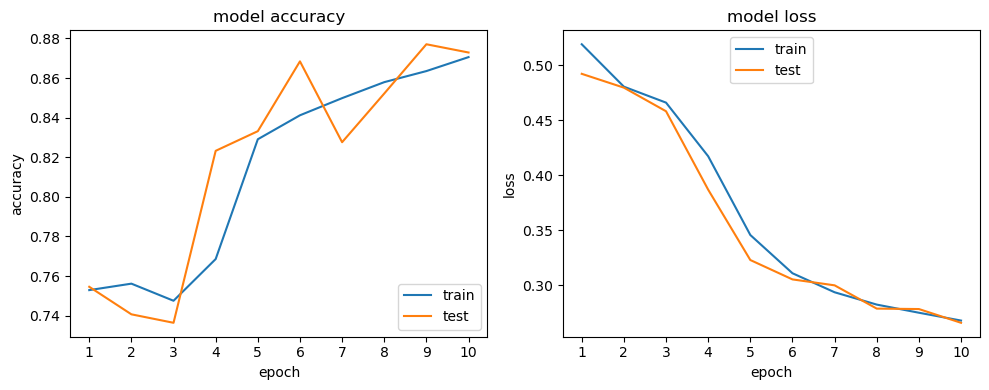

In [253]:
viz_loss(dict(grid_result2.best_estimator_.history_))

In [263]:
predicciones = pd.DataFrame(data=grid_result2.predict_proba(X_test), columns=['pred_0', 'pred_1'])

132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


##### Calculamos el AUC

In [265]:
auc = roc_auc_score(y_test, predicciones['pred_1'])
print(f"AUC: {auc:.3f}")

AUC: 0.950


##### Calculamos la Curva ROC

In [269]:
fpr, tpr, thresholds = roc_curve(y_test, predicciones['pred_1'])

##### Graficamos de la curva ROC

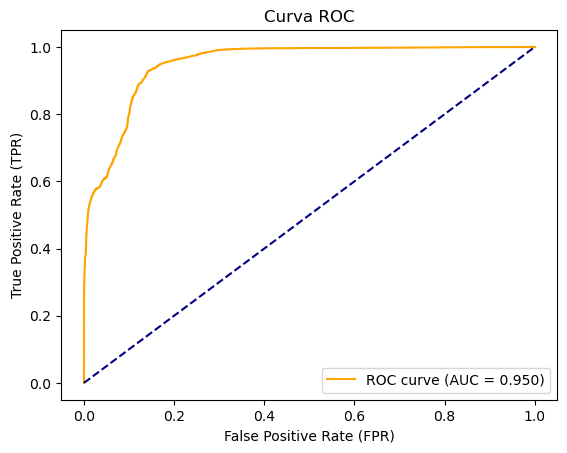

El área bajo la curva en TEST es:  0.9497339050951209


In [273]:
plt.figure()
plt.plot(fpr, tpr, color='orange', label=f'ROC curve (AUC = {auc:.3f})')
plt.plot([0, 1], [0, 1], color='navy', linestyle='--')  # Línea de referencia
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('Curva ROC')
plt.legend(loc="lower right")
plt.show()

print('El área bajo la curva en TEST es: ', auc)

##### Determinamos el umbral óptimo

In [276]:
optimal_idx = np.argmax(tpr - fpr)
optimal_threshold = thresholds[optimal_idx]

##### Convertimos las probabilidades en etiquetas usando el umbral óptimo

In [281]:
y_test_pred = np.where(predicciones['pred_1'] > optimal_threshold, 1, 0)

##### Evaluamos el desempeño del modelo

In [285]:
print('Los métricas usando el thereshold óptimo son: ')
print(classification_report(y_test, y_test_pred))    
print('La matriz de confusión: ')
print(confusion_matrix(y_test, y_test_pred))

Los métricas usando el thereshold óptimo son: 
              precision    recall  f1-score   support

         0.0       0.95      0.86      0.90     24742
         1.0       0.79      0.93      0.86     14650

    accuracy                           0.88     39392
   macro avg       0.87      0.89      0.88     39392
weighted avg       0.89      0.88      0.89     39392

La matriz de confusión: 
[[21220  3522]
 [ 1056 13594]]


Podemos ver que el segundo modelo logró tener un accuracy de 0.88, lo cual indica que tiene un muy buena precisión. De igual manera, como habíamos mencionado antes, esto también fue posible gracias de haber implementado la búsqueda de grilla.

##### Conclusiones respecto a los 2 modelos que vimos:

El primero modelo vendría a ser el mejor a implementar debido a que durante el apredizaje las líneas de entrenamiento y de test están más a la par. Lo que permite que el modelo no tenga posteriormente sesgo o sobre ajustado si en caso las épocas hubieras sido mucho más de las que se pusieron. Esto se puede ver en el gráfico de model accuracy y model loss.

Por otro lado, las métricas de precision, recall y f1-score están mejores, pero la diferencia es mínima.

Cabe destacar ambos modelos redes neuronales multicapa son bastante buenos.

#### Pregunta 4

4. Construye una red neuronal con regularización Dropout aplicando búsqueda de grilla para tres fold. El modelo debe conseguir un *accuracy* superior al 80%. La búsqueda debe sintonizar los siguientes hiperparámetros:

    - a. Cantidad de capas ocultas: de 3 o 4
    - b. Método de optimización: Adam o SGD
    - c. learning_rate: 0.03 y 0.06
    - d. Cantidad de neuronas en las capas ocultas: 20
    - e. Funciones de activación en las capas ocultas: tanh
    - f. Rate para Dropout: 0.001
    - g. Inicialización de los pesos: [glorot_normal, glorot_uniform]  

Debes mostrar los hiperparámetros óptimos encontrados por la búsqueda de grilla. Calcula además las métricas asociadas a la matriz de confusión al aplicar el modelo con los hiperparámetros óptimos al conjunto de test. Muestra la curva ROC para el mejor modelo incluyendo el AUC.


In [387]:
def create_model_4( ini_pesos =GlorotNormal() ,dropout_rate=0.001, hl = 3,n_neurons=80,  meta={}):
    n_features_in_ = meta["n_features_in_"]
    X_shape_ = meta["X_shape_"]
    
    ann_tmp = Sequential()
    ann_tmp.add(keras.Input(shape=(n_features_in_, )))   

    
    activation_fn = 'tanh'
    
    for _ in range(hl):
    
        ann_tmp.add(
            Dense(
                units=n_neurons,
                use_bias=True,
                activation=activation_fn,
                kernel_initializer=ini_pesos
            )
        )
        ann_tmp.add(Dropout(rate=dropout_rate))     
    ann_tmp.add(
        Dense(
            units=1,
            activation='sigmoid',
            kernel_initializer=ini_pesos,
            bias_initializer='zeros'
        )
    )
    return ann_tmp

In [389]:
clf4 = KerasClassifier(
    create_model_4,
    loss='hinge',
    verbose=1,
    metrics=['accuracy'],
    validation_split=.33
)

In [391]:
param_grid4 = {
    'model__n_neurons': [20],
    'batch_size': [300],
    'epochs': [30],
    'optimizer__learning_rate': [0.03 , 0.06],
    'optimizer': ['Adam' , 'SGD'],
    'model__hl': [3, 4],
    'model__dropout_rate': [0.001],
    'model__ini_pesos': [GlorotNormal(), GlorotUniform()]
}
grid4 = GridSearchCV(estimator=clf4, param_grid=param_grid4,
    scoring='accuracy', cv=5, verbose=0, n_jobs=-1)

grid_result4 = grid4.fit(X_train, y_train)

Epoch 1/30
179/179 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.5660 - loss: 1.0810 - val_accuracy: 0.6461 - val_loss: 0.9940
Epoch 2/30
179/179 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.6982 - loss: 0.9697 - val_accuracy: 0.7461 - val_loss: 0.9093
Epoch 3/30
179/179 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7548 - loss: 0.8983 - val_accuracy: 0.7471 - val_loss: 0.8919
Epoch 4/30
179/179 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7584 - loss: 0.8871 - val_accuracy: 0.7475 - val_loss: 0.8869
Epoch 5/30
179/179 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7529 - loss: 0.8824 - val_accuracy: 0.7476 - val_loss: 0.8848
Epoch 6/30
179/179 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7589 - loss: 0.8839 - val_accuracy: 0.7478 - val_loss: 0.8836
Epoch 7/30
179/179 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7564 - loss: 0.8792 - val_accuracy: 0.7479 - val_loss: 0.8828
Epoch 8/30
179/179 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7558 - loss: 0.8824 - val_accuracy: 0.

##### Mostramos los hiperparámetros óptimos encontrados por la búsqueda de grilla.

In [393]:
print("\n\nBest: %f using %s" % (grid_result4.best_score_, grid_result4.best_params_))



Best: 0.752732 using {'batch_size': 300, 'epochs': 30, 'model__dropout_rate': 0.001, 'model__hl': 4, 'model__ini_pesos': <keras.src.initializers.random_initializers.GlorotUniform object at 0x00000140BEF20560>, 'model__n_neurons': 20, 'optimizer': 'SGD', 'optimizer__learning_rate': 0.03}


En la mejor interacción del modelo donde logra un 0.752732 tiene 4 capas, usa GlorotUniform, tiene 20 neuronas, tiene como optimizer SGD y tiene una tasa de aprendizaje de 0.03.

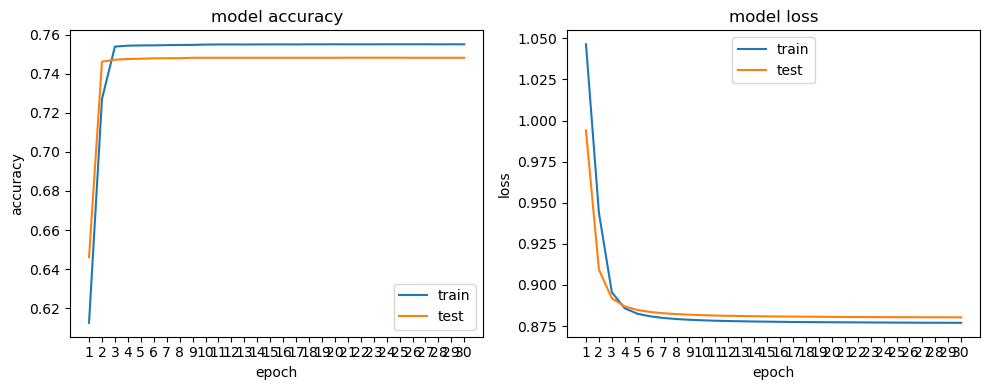

In [396]:
viz_loss(dict(grid_result4.best_estimator_.history_))

In [398]:
# Las predicciones se han realizado a partir del modelo con los hiper paramétros óptimos
predicciones = pd.DataFrame(data=grid_result4.best_estimator_.predict_proba(X_test), columns=['pred_0', 'pred_1'])

132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


##### De la pregunta 4

##### Calculamos las métricas asociadas a la matriz de confusión al aplicar el modelo con los hiper paramétros óptimos al conjunto de test.

En primera instancia, calculamos las variables para realizar la Curva ROC debido a que necesitamos convertir las probabilidades en etiquetas usando el umbral óptimo

In [400]:
fpr, tpr, thresholds = roc_curve(y_test, predicciones['pred_1'])

##### Determinamos el umbral óptimo

In [402]:
optimal_idx = np.argmax(tpr - fpr)
optimal_threshold = thresholds[optimal_idx]

##### Convertimos las probabilidades en etiquetas usando el umbral óptimo

In [404]:
y_test_pred = np.where(predicciones['pred_1'] > optimal_threshold, 1, 0)

##### Evaluamos el desempeño del modelo

In [406]:
print('Los métricas usando el thereshold óptimo son: ')
print(classification_report(y_test, y_test_pred))    
print('La matriz de confusión: ')
print(confusion_matrix(y_test, y_test_pred))

Los métricas usando el thereshold óptimo son: 
              precision    recall  f1-score   support

         0.0       0.77      0.67      0.71     24742
         1.0       0.54      0.66      0.59     14650

    accuracy                           0.66     39392
   macro avg       0.65      0.66      0.65     39392
weighted avg       0.68      0.66      0.67     39392

La matriz de confusión: 
[[16545  8197]
 [ 5025  9625]]


##### Muestramos la curva ROC para el mejor modelo incluyendo el AUC.

##### Calculamos el AUC

In [409]:
auc = roc_auc_score(y_test, predicciones['pred_1'])
print(f"AUC: {auc:.3f}")

AUC: 0.718


##### Graficamos de la curva ROC

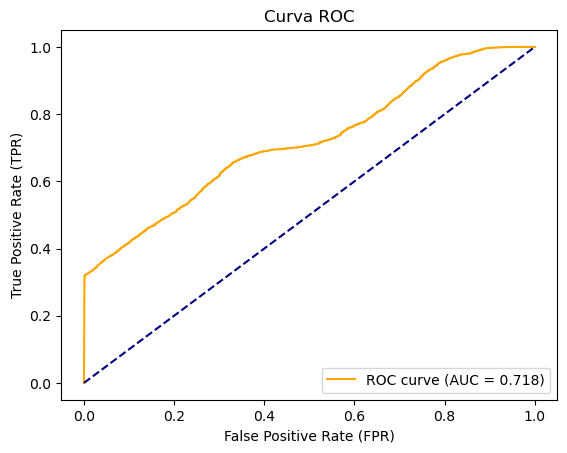

El área bajo la curva en TEST es:  0.7181267748005837


In [411]:
plt.figure()
plt.plot(fpr, tpr, color='orange', label=f'ROC curve (AUC = {auc:.3f})')
plt.plot([0, 1], [0, 1], color='navy', linestyle='--')  # Línea de referencia
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('Curva ROC')
plt.legend(loc="lower right")
plt.show()

print('El área bajo la curva en TEST es: ', auc)

In [413]:
predicciones

,pred_0,pred_1
0,0.002855,0.997145
1,0.999476,0.000524
2,0.999549,0.000451
3,0.999274,0.000726
4,0.001018,0.998982
...,...,...
39387,0.999298,0.000702
39388,0.999528,0.000472
39389,0.001170,0.998830
39390,0.999095,0.000905


##### Conclusiones

Podemos decir que el modelo no logró tener unas buenas métricas a pesar de haberle hecho varios cambios como fueron colocar más épocas, colocar un mayor cv, aplicar smote, cambiar las variables del dataframe entre otros.

#### Pregunta 5

5. Del conjunto original (sin los valores excluidos) escoge al azar cinco observaciones en que **deposit_type_Non Refund** sea cero, y con esto realiza una predicción usando el mejor modelo encontrado por la búsqueda de grilla anterior. Comenta los resultados.

In [416]:
df_concat.head(5)

,lead_time,booking_changes,previous_cancellations,total_of_special_requests,adr,is_canceled,deposit_type_Non Refund,deposit_type_Refundable
1,-0.973361,-0.338966,-0.103184,-0.720693,-2.431686,0.0,0,0
2,-0.673908,-0.338966,-0.103184,0.540652,-2.431686,0.0,0,0
3,-0.870424,-0.338966,-0.103184,0.540652,-2.431686,0.0,0,0
4,-0.093719,-0.338966,-0.103184,-0.720693,-2.431686,0.0,0,0
5,-0.645835,-0.338966,-0.103184,-0.720693,-2.431686,0.0,0,0


In [424]:
df_concat[df_concat['deposit_type_Non Refund'] == 0].head(5)

,lead_time,booking_changes,previous_cancellations,total_of_special_requests,adr,is_canceled,deposit_type_Non Refund,deposit_type_Refundable
1,-0.973361,-0.338966,-0.103184,-0.720693,-2.431686,0.0,0,0
2,-0.673908,-0.338966,-0.103184,0.540652,-2.431686,0.0,0,0
3,-0.870424,-0.338966,-0.103184,0.540652,-2.431686,0.0,0,0
4,-0.093719,-0.338966,-0.103184,-0.720693,-2.431686,0.0,0,0
5,-0.645835,-0.338966,-0.103184,-0.720693,-2.431686,0.0,0,0


In [430]:
# escogo al azar 5 observaciones donde deposit_type_Non Refund == 0
df_0 = df_concat[df_concat['deposit_type_Non Refund'] == 0]
df_sample = df_0.sample(n = 5)

# separo mis conjunto de datos
X_sample = df_sample.drop(columns='is_canceled')
y_sample = df_sample['is_canceled']

# realizo la prediccion
y_pred = grid_result4.best_estimator_.predict(X_sample)

# coloco en un dataframe los datos reales y los predichos.
predicciones_5 = pd.DataFrame({
    'real': y_sample,
    'prediccion': y_pred
})

predicciones_5

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step


,real,prediccion
34933,0.0,0.0
91704,0.0,0.0
4799,0.0,0.0
26858,0.0,0.0
76335,0.0,0.0


Podemos indicar de que a pesar de que el modelo de la pregunta 4 no tenga un buen accuracy, en este caso predijo adecuadamente los valores.

Sin embargo, no es un buen modelo a implementar por las métricas bajas que tiene.